In [ ]:
# DS 4002 — Project 3: Vehicle Body-Type Classification Across Viewing Angles
# Team: The Pink Panthers — Shawn Chen and Zichen Luo
# Data preparation: Shawn Chen
#
# PURPOSE
# Apply saved human-review decisions to candidate vehicle images, verify
# retained files, and create fixed training/validation/test splits by model.
#
# PLATFORM AND PACKAGES
# Run in Google Colab with Python 3, pandas, NumPy, and Pillow.
# The notebook uses Colab upload/download functions and /content paths.
#
# INPUTS
# First upload: DVM_Project3_Review_20261114_201843_029683.zip
# Contains selection_manifest.csv, candidate images, and DATA_LICENSE.txt.
# Second upload: DVM_Review_Records.zip
# Contains listing_review.csv with recorded human-review decisions.
#
# EXECUTION
# Start a fresh runtime and run all code cells from top to bottom.
# Upload only the requested ZIP at each prompt.
# This notebook applies existing review decisions; it does not perform
# visual review or recreate the earlier raw-metadata candidate selection.
#
# OUTPUTS
# Dataset folder: /content/DVM_Cleaned_Data/
# Downloadable archive: /content/DVM_Cleaned_Data.zip
# Includes verified images, manifests, review records, and split configuration.
# Files are not automatically uploaded to GitHub.
#
# VALIDATION
# Expected cleaned sample: 860 listings and 2,580 images.
# Each listing has Front, Side, and Rear views.
# Splits keep every Genmodel_ID in one partition.
# Failed assertions stop execution for investigation.

In [ ]:
# Import tools for file paths, CSV processing, numerical operations,
# ZIP archives, SHA-256 hashes, and image decoding.
# Pillow is imported as PIL. These imports are used by later cells.
from pathlib import Path
import pandas as pd
import numpy as np
import zipfile
import hashlib
import io
from PIL import Image

print("Ready")

Ready


In [ ]:
# Upload the original candidate-image ZIP into the Colab runtime.
# Select DVM_Project3_Review_20261114_201843_029683.zip.
# This archive supplies the candidate manifest and image files.
from google.colab import files

uploaded = files.upload()

Saving DVM_Cleaned_Data.zip to DVM_Cleaned_Data.zip


In [ ]:
# MI3 — ResNet-18 model development and evaluation
# Uses the fixed train/validation/test manifests from DVM_Cleaned_Data.zip.
from pathlib import Path
import zipfile, json, random, os, time, copy
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import balanced_accuracy_score, f1_score, confusion_matrix, classification_report

SEED=4002
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic=True; torch.backends.cudnn.benchmark=False
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
zip_path=Path('/content/DVM_Cleaned_Data.zip')
data_root=Path('/content/DVM_Cleaned_Data')
assert zip_path.exists(), 'Upload DVM_Cleaned_Data.zip first.'
if not data_root.exists():
    with zipfile.ZipFile(zip_path) as z: z.extractall('/content')
# Handle archives with or without a top-level DVM_Cleaned_Data folder.
if not (data_root/'train_manifest.csv').exists():
    hits=list(Path('/content').rglob('train_manifest.csv'))
    assert len(hits)==1, hits
    data_root=hits[0].parent
print('device:',device,'root:',data_root)
for split in ['train','validation','test']:
    p=data_root/f'{split}_manifest.csv'
    d=pd.read_csv(p,dtype=str).fillna('')
    print(split,d.shape,list(d.columns))
    print(d.head(2).to_string(index=False))

device: cuda root: /content/DVM_Cleaned_Data
train (1785, 20) ['Review_ID', 'Body_type', 'Maker', 'Genmodel', 'Genmodel_ID', 'Adv_ID', 'View', 'Image_ID', 'Image_name', 'Predicted_viewpoint', 'Quality_check', 'Source_relative_path', 'Extracted_path', 'File_SHA256', 'Class_id', 'Filename', 'Human_review_status', 'Human_reviewer', 'Human_review_date', 'Split']
Review_ID Body_type      Maker Genmodel Genmodel_ID    Adv_ID  View      Image_ID                                               Image_name Predicted_viewpoint Quality_check                                                                  Source_relative_path                                            Extracted_path                                                      File_SHA256 Class_id                                           Filename Human_review_status Human_reviewer Human_review_date Split
        6     Sedan Alfa Romeo   Giulia        4_10 4_10$$113 Front 4_10$$113$$13 Alfa Romeo$$Giulia$$2018$$White$$4_10$$113$$image_13.jpg

In [ ]:
# MI3 model development: validation-based selection and final ResNet-18 fine-tuning
label_names=['Sedan','SUV','Pickup']
num_classes=3
output_dir=Path('/content/MI3_OUTPUT'); output_dir.mkdir(exist_ok=True)

def resolve_image(raw):
    raw=str(raw).replace('\\','/')
    p=Path(raw)
    candidates=[p, data_root/raw, Path('/content')/raw]
    if 'DVM_Cleaned_Data/' in raw:
        candidates.append(data_root/raw.split('DVM_Cleaned_Data/',1)[1])
    for c in candidates:
        if c.exists(): return c
    raise FileNotFoundError(raw)

class VehicleDataset(Dataset):
    def __init__(self, csv_path, transform):
        self.df=pd.read_csv(csv_path,dtype=str).fillna('')
        self.transform=transform
        self.paths=[resolve_image(x) for x in self.df['Extracted_path']]
        self.labels=self.df['Class_id'].astype(int).tolist()
    def __len__(self): return len(self.df)
    def __getitem__(self,i):
        with Image.open(self.paths[i]) as im: image=im.convert('RGB')
        return self.transform(image), self.labels[i], i

train_tf=transforms.Compose([
    transforms.Resize(256), transforms.RandomResizedCrop(224,scale=(0.80,1.0)),
    transforms.RandomHorizontalFlip(), transforms.ColorJitter(0.15,0.15,0.15,0.05),
    transforms.ToTensor(), transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])
eval_tf=transforms.Compose([transforms.Resize(256),transforms.CenterCrop(224),transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])
train_ds=VehicleDataset(data_root/'train_manifest.csv',train_tf)
val_ds=VehicleDataset(data_root/'validation_manifest.csv',eval_tf)
test_ds=VehicleDataset(data_root/'test_manifest.csv',eval_tf)
assert len(train_ds)==1785 and len(val_ds)==393 and len(test_ds)==402
BATCH=64
train_loader=DataLoader(train_ds,batch_size=BATCH,shuffle=True,num_workers=2,pin_memory=True)
val_loader=DataLoader(val_ds,batch_size=BATCH,shuffle=False,num_workers=2,pin_memory=True)
test_loader=DataLoader(test_ds,batch_size=BATCH,shuffle=False,num_workers=2,pin_memory=True)
counts=np.bincount(train_ds.labels,minlength=3)
class_weights=torch.tensor(len(train_ds)/(3*counts),dtype=torch.float32,device=device)
print('class counts:',dict(zip(label_names,counts)),'weights:',class_weights.cpu().numpy().round(3))

def make_model():
    m=models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    m.fc=nn.Linear(m.fc.in_features,num_classes)
    return m.to(device)

def predict(model,loader):
    model.eval(); ys=[]; ps=[]; idxs=[]
    with torch.no_grad():
        for x,y,i in loader:
            x=x.to(device,non_blocking=True)
            with torch.cuda.amp.autocast(enabled=device.type=='cuda'):
                logits=model(x)
            ys.extend(y.numpy()); ps.extend(logits.argmax(1).cpu().numpy()); idxs.extend(i.numpy())
    return np.array(ys),np.array(ps),np.array(idxs)

def fit(setting,max_epochs,patience=2):
    model=make_model()
    opt=torch.optim.AdamW(model.parameters(),lr=setting['lr'],weight_decay=setting['weight_decay'])
    sched=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='max',factor=.3,patience=1)
    loss_fn=nn.CrossEntropyLoss(weight=class_weights)
    scaler=torch.cuda.amp.GradScaler(enabled=device.type=='cuda')
    best_state=None; best_f1=-1; wait=0; history=[]
    for epoch in range(1,max_epochs+1):
        model.train(); total=0; correct=0; loss_sum=0
        for x,y,_ in train_loader:
            x=x.to(device,non_blocking=True); y=y.to(device,non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=device.type=='cuda'):
                logits=model(x); loss=loss_fn(logits,y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            loss_sum+=loss.item()*len(y); total+=len(y); correct+=(logits.argmax(1)==y).sum().item()
        vy,vp,_=predict(model,val_loader)
        vf1=f1_score(vy,vp,average='macro'); vbal=balanced_accuracy_score(vy,vp)
        sched.step(vf1)
        row={'epoch':epoch,'train_loss':loss_sum/total,'train_acc':correct/total,'val_macro_f1':vf1,'val_balanced_accuracy':vbal}
        history.append(row); print(setting,'epoch',epoch,{k:round(v,4) for k,v in row.items() if k!='epoch'})
        if vf1>best_f1+1e-4:
            best_f1=vf1; best_state=copy.deepcopy(model.state_dict()); wait=0
        else:
            wait+=1
            if wait>=patience: break
    model.load_state_dict(best_state)
    return model,pd.DataFrame(history),best_f1

settings=[{'lr':1e-3,'weight_decay':1e-4},{'lr':3e-4,'weight_decay':1e-4}]
tuning=[]
for s in settings:
    _,h,score=fit(s,max_epochs=3,patience=2)
    tuning.append({**s,'best_val_macro_f1':score,'epochs_run':len(h)})
tuning_df=pd.DataFrame(tuning).sort_values('best_val_macro_f1',ascending=False)
display(tuning_df); tuning_df.to_csv(output_dir/'validation_tuning_results.csv',index=False)
best_setting={k:float(tuning_df.iloc[0][k]) for k in ['lr','weight_decay']}
print('Selected by validation macro F1:',best_setting)
final_model,history_df,best_val_f1=fit(best_setting,max_epochs=8,patience=3)
torch.save({'model_state':final_model.state_dict(),'setting':best_setting,'seed':SEED,'labels':label_names},output_dir/'resnet18_best.pt')
history_df.to_csv(output_dir/'training_history.csv',index=False)
print('Final checkpoint validation macro F1:',round(best_val_f1,4))

class counts: {'Sedan': np.int64(825), 'SUV': np.int64(768), 'Pickup': np.int64(192)} weights: [0.721 0.775 3.099]
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 85.0MB/s]
/tmp/ipykernel_822/746237461.py:65: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler=torch.cuda.amp.GradScaler(enabled=device.type=='cuda')
/tmp/ipykernel_822/746237461.py:72: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=='cuda'):
/tmp/ipykernel_822/746237461.py:55: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=='cuda'):


{'lr': 0.001, 'weight_decay': 0.0001} epoch 1 {'train_loss': 0.7579, 'train_acc': 0.707, 'val_macro_f1': 0.7298, 'val_balanced_accuracy': np.float64(0.7562)}


/tmp/ipykernel_822/746237461.py:72: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=='cuda'):
/tmp/ipykernel_822/746237461.py:55: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=='cuda'):


{'lr': 0.001, 'weight_decay': 0.0001} epoch 2 {'train_loss': 0.2581, 'train_acc': 0.9008, 'val_macro_f1': 0.7855, 'val_balanced_accuracy': np.float64(0.7568)}


/tmp/ipykernel_822/746237461.py:72: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=='cuda'):
/tmp/ipykernel_822/746237461.py:55: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=='cuda'):


... (21 outputs left out)

/tmp/ipykernel_822/746237461.py:72: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=='cuda'):
/tmp/ipykernel_822/746237461.py:55: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=='cuda'):


{'lr': 0.001, 'weight_decay': 0.0001} epoch 7 {'train_loss': 0.027, 'train_acc': 0.9905, 'val_macro_f1': 0.8674, 'val_balanced_accuracy': np.float64(0.8469)}


/tmp/ipykernel_822/746237461.py:72: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=='cuda'):
/tmp/ipykernel_822/746237461.py:55: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=='cuda'):


{'lr': 0.001, 'weight_decay': 0.0001} epoch 8 {'train_loss': 0.0174, 'train_acc': 0.9944, 'val_macro_f1': 0.8753, 'val_balanced_accuracy': np.float64(0.851)}
Final checkpoint validation macro F1: 0.8753


/tmp/ipykernel_822/746237461.py:55: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=='cuda'):


FINAL TEST METRICS


,scope,n,balanced_accuracy,macro_f1
0,Overall,402,0.8246,0.8492
1,Front,134,0.5322,0.4946
2,Side,134,0.9649,0.9596
3,Rear,134,0.9766,0.9766


              precision    recall  f1-score   support

       Sedan     0.9321    0.8830    0.9069       171
         SUV     0.7980    0.9240    0.8564       171
      Pickup     0.9524    0.6667    0.7843        60

    accuracy                         0.8682       402
   macro avg     0.8942    0.8246    0.8492       402
weighted avg     0.8781    0.8682    0.8671       402



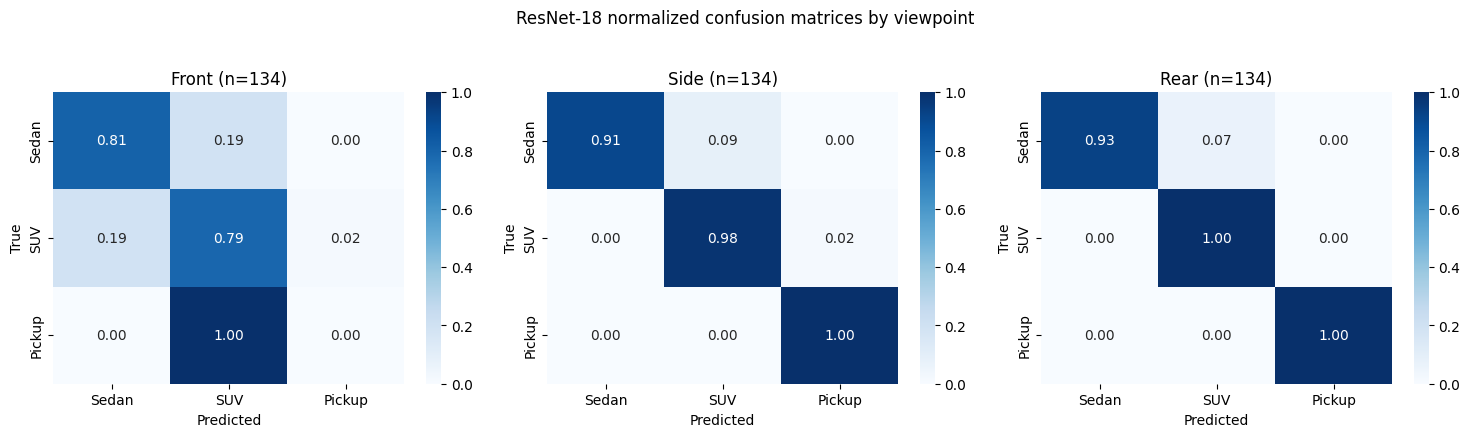

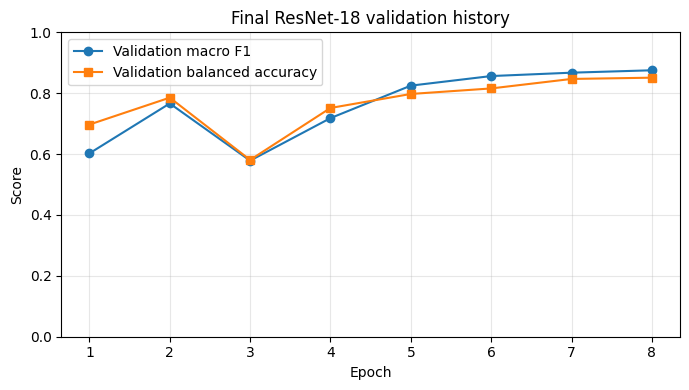

INTERPRETATION
The validation-selected ResNet-18 achieved test balanced accuracy 0.825 and macro F1 0.849, exceeding the 0.333 chance benchmark. Rear was strongest (balanced accuracy 0.977); Front was weakest (0.532). Differences are consistent with viewpoint-specific visual information: side views expose silhouette and pickup-bed structure, while front/rear views can make sedan-versus-SUV proportions less distinct.

LIMITATIONS
The test set contains only 402 images (134 matched listings), and Pickup is the minority class, so its recall has greater sampling uncertainty. Three images from each listing are correlated rather than independent, even though vehicle-model grouping prevents model leakage across splits. DVM-CAR images may contain background, lighting, and dealership-style cues, limiting generalization to other countries or image sources. Only two learning rates were compared under one augmentation and optimizer design; validation selection therefore does not establish a globall

In [ ]:
# MI3 final held-out test evaluation (test set was not used for setting selection)
ty,tp,tidx=predict(final_model,test_loader)
test_meta=test_ds.df.iloc[tidx].reset_index(drop=True).copy()
test_meta['y_true']=ty; test_meta['y_pred']=tp
metrics=[]
def metric_row(scope,y,p):
    return {'scope':scope,'n':len(y),'balanced_accuracy':balanced_accuracy_score(y,p),'macro_f1':f1_score(y,p,average='macro')}
metrics.append(metric_row('Overall',ty,tp))
for view in ['Front','Side','Rear']:
    m=test_meta['View'].str.lower().eq(view.lower())
    metrics.append(metric_row(view,test_meta.loc[m,'y_true'],test_meta.loc[m,'y_pred']))
metrics_df=pd.DataFrame(metrics)
print('FINAL TEST METRICS'); display(metrics_df.round(4))
metrics_df.to_csv(output_dir/'test_metrics_overall_and_by_view.csv',index=False)
test_meta.to_csv(output_dir/'test_predictions.csv',index=False)
report=classification_report(ty,tp,target_names=label_names,digits=4,zero_division=0)
print(report)
(output_dir/'classification_report.txt').write_text(report)

# Normalized confusion matrix for each viewpoint; rows sum to 1.
fig,axes=plt.subplots(1,3,figsize=(15,4.2))
for ax,view in zip(axes,['Front','Side','Rear']):
    m=test_meta['View'].str.lower().eq(view.lower())
    cm=confusion_matrix(test_meta.loc[m,'y_true'],test_meta.loc[m,'y_pred'],labels=[0,1,2],normalize='true')
    sns.heatmap(cm,annot=True,fmt='.2f',cmap='Blues',vmin=0,vmax=1,xticklabels=label_names,yticklabels=label_names,ax=ax)
    ax.set_title(f'{view} (n={m.sum()})'); ax.set_xlabel('Predicted'); ax.set_ylabel('True')
plt.suptitle('ResNet-18 normalized confusion matrices by viewpoint',y=1.03)
plt.tight_layout(); plt.savefig(output_dir/'confusion_matrices_by_viewpoint.png',dpi=200,bbox_inches='tight'); plt.show()

fig,ax=plt.subplots(figsize=(7,4))
ax.plot(history_df.epoch,history_df.val_macro_f1,marker='o',label='Validation macro F1')
ax.plot(history_df.epoch,history_df.val_balanced_accuracy,marker='s',label='Validation balanced accuracy')
ax.set(xlabel='Epoch',ylabel='Score',title='Final ResNet-18 validation history',ylim=(0,1)); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(output_dir/'validation_training_curve.png',dpi=200); plt.show()

# Evidence-based interpretation text for the report.
best_view=metrics_df.iloc[1:].sort_values('balanced_accuracy',ascending=False).iloc[0]
worst_view=metrics_df.iloc[1:].sort_values('balanced_accuracy').iloc[0]
interpretation=f'''INTERPRETATION
The validation-selected ResNet-18 achieved test balanced accuracy {metrics_df.iloc[0].balanced_accuracy:.3f} and macro F1 {metrics_df.iloc[0].macro_f1:.3f}, exceeding the 0.333 chance benchmark. {best_view.scope} was strongest (balanced accuracy {best_view.balanced_accuracy:.3f}); {worst_view.scope} was weakest ({worst_view.balanced_accuracy:.3f}). Differences are consistent with viewpoint-specific visual information: side views expose silhouette and pickup-bed structure, while front/rear views can make sedan-versus-SUV proportions less distinct.

LIMITATIONS
The test set contains only 402 images (134 matched listings), and Pickup is the minority class, so its recall has greater sampling uncertainty. Three images from each listing are correlated rather than independent, even though vehicle-model grouping prevents model leakage across splits. DVM-CAR images may contain background, lighting, and dealership-style cues, limiting generalization to other countries or image sources. Only two learning rates were compared under one augmentation and optimizer design; validation selection therefore does not establish a globally optimal configuration. Results apply to the three retained body-type labels and should not be generalized to finer vehicle categories.'''
print(interpretation)
(output_dir/'interpretation_and_limitations.txt').write_text(interpretation)

# Reproducible output bundle (checkpoint kept separately because of size).
import shutil
shutil.make_archive('/content/MI3_results','zip',output_dir)
print('Saved outputs:',sorted(p.name for p in output_dir.iterdir()))
print('Bundle: /content/MI3_results.zip')

MI3 — Model Development and Evaluation
Validation-based model selection
We fine-tuned an ImageNet-pretrained ResNet-18 for the three retained body-type classes (Sedan, SUV, and Pickup). Training used ImageNet normalization, train-only augmentation, class-weighted cross-entropy, AdamW, a ReduceLROnPlateau scheduler, and model-level train/validation/test splits to prevent images from the same listing model from leaking across partitions. The random seed was fixed at 4002.
Two learning rates were compared on the validation set while holding weight decay at 0.0001. Learning rate 0.001 achieved the stronger trial validation macro F1 (0.8507 versus 0.8247 for 0.0003), so it was selected. After eight full-network fine-tuning epochs, the saved checkpoint reached validation macro F1 = 0.8753 and balanced accuracy = 0.8510.
Final test performance
Scope
n
Balanced accuracy
Macro F1
Overall
402
0.8246
0.8492
Front
134
0.5322
0.4946
Side
134
0.9649
0.9596
Rear
134
0.9766
0.9766
Overall accuracy was 0.8682. Pickup was the most difficult class by recall (0.6667), despite high precision (0.9524), indicating that many true pickups were conservatively assigned to another body type. The normalized confusion matrices above provide the required viewpoint-level error breakdown.
Interpretation
Rear-view performance was strongest, closely followed by side-view performance, whereas front-view performance was much weaker. Side images expose silhouette, ride height, and pickup-bed structure. Rear images in this sample also expose tailgate/cargo-bed geometry and vehicle proportions that distinguish pickups and SUVs. By contrast, front views suppress much of the length and cargo-area information, making sedan-versus-SUV and SUV-versus-pickup distinctions less identifiable. Therefore, the overall score masks a major viewpoint-dependent failure mode.
Limitations
The test set has only 402 images from 134 matched listings; uncertainty is therefore substantial, especially after stratifying by viewpoint.
Pickup is the minority class, so its recall estimate is based on only 60 test images and is less stable than the Sedan and SUV estimates.
The three views from one listing are correlated observations. Splitting by model reduces leakage but does not make viewpoints statistically independent.
Dealership backgrounds, framing, lighting, and dataset-specific image conventions may become shortcuts, limiting generalization to street photos or other marketplaces.
Hyperparameter search was intentionally small (two learning rates with fixed weight decay); broader tuning, cross-validation, and additional architectures could improve robustness.
Conclusions apply only to the three retained labels and should not be generalized to excluded or ambiguous body types.
Reproducibility artifacts
The notebook writes the best checkpoint, validation tuning table, training history, overall and viewpoint metrics, test-level predictions, classification report, training curve, normalized viewpoint confusion matrices, and interpretation text to /content/MI3_OUTPUT, then packages them as /content/MI3_results.zip.


In [ ]:
from google.colab import files
files.download('/content/MI3_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import zipfile, os, json, pandas as pd, numpy as np
from pathlib import Path

zip_names = [name for name in uploaded if name.lower().endswith('.zip')]
assert len(zip_names) == 1, f'Expected one uploaded ZIP, found {zip_names}'
source_zip = Path(zip_names[0])
with zipfile.ZipFile(source_zip) as z:
    names = z.namelist()
print('ZIP:', source_zip, 'files:', len(names))
print('First 80 entries:')
print('\n'.join(names[:80]))
print('Extensions:', pd.Series([Path(n).suffix.lower() for n in names]).value_counts().head(20).to_dict())b

ZIP: tables_V2.0.zip files: 8
First 80 entries:
/
Ad_table.csv
Trim_table.csv
Basic_table.csv
Sales_table.csv
Price_table.csv
Image_table.csv
Ad_table (extra).csv
Extensions: {'.csv': 7, '': 1}


KeyError: "There is no item named 'selection_manifest.csv' in the archive"

In [ ]:
import zipfile, io, pandas as pd
from pathlib import Path
with zipfile.ZipFile(source_zip) as z:
    for fn in [n for n in z.namelist() if n.lower().endswith('.csv')]:
        df0 = pd.read_csv(z.open(fn), nrows=5)
        print('\n---', fn, '---')
        print('columns:', list(df0.columns))
        print(df0.head(2).to_string(index=False))


--- Ad_table.csv ---
columns: ['Maker', 'Genmodel', 'Genmodel_ID', 'Adv_ID', 'Adv_year', 'Adv_month', 'Color', 'Reg_year', 'Bodytype', 'Runned_Miles', 'Engin_size', 'Gearbox', 'Fuel_type', 'Price', 'Seat_num', 'Door_num']
  Maker Genmodel Genmodel_ID  Adv_ID  Adv_year  Adv_month  Color  Reg_year Bodytype  Runned_Miles Engin_size   Gearbox Fuel_type  Price  Seat_num  Door_num
Bentley   Arnage        10_1 10_1$$1      2018          4 Silver      2000   Saloon         60000       6.8L Automatic    Petrol  21500         5         4
Bentley   Arnage        10_1 10_1$$2      2018          6   Grey      2002   Saloon         44000       6.8L Automatic    Petrol  28750         5         4

--- Trim_table.csv ---
columns: ['Genmodel_ID', 'Maker', 'Genmodel', 'Trim', 'Year', 'Price', 'Gas_emission', 'Fuel_type', 'Engine_size']
Genmodel_ID  Maker   Genmodel                                                            Trim  Year  Price  Gas_emission Fuel_type  Engine_size
        2_1 Abarth 124 spi

In [ ]:
with zipfile.ZipFile(source_zip) as z:
    for fn in [n for n in z.namelist() if n.lower().endswith('.csv')]:
        d = pd.read_csv(z.open(fn), low_memory=False)
        print(f'{fn}: shape={d.shape}; columns={list(d.columns)}')

Ad_table.csv: shape=(268255, 16); columns=['Maker', 'Genmodel', 'Genmodel_ID', 'Adv_ID', 'Adv_year', 'Adv_month', 'Color', 'Reg_year', 'Bodytype', 'Runned_Miles', 'Engin_size', 'Gearbox', 'Fuel_type', 'Price', 'Seat_num', 'Door_num']
Trim_table.csv: shape=(335562, 9); columns=['Genmodel_ID', 'Maker', 'Genmodel', 'Trim', 'Year', 'Price', 'Gas_emission', 'Fuel_type', 'Engine_size']
Basic_table.csv: shape=(1011, 4); columns=['Automaker', 'Automaker_ID', 'Genmodel', 'Genmodel_ID']
Sales_table.csv: shape=(773, 23); columns=['Maker', 'Genmodel', 'Genmodel_ID', '2020', '2019', '2018', '2017', '2016', '2015', '2014', '2013', '2012', '2011', '2010', '2009', '2008', '2007', '2006', '2005', '2004', '2003', '2002', '2001']
Price_table.csv: shape=(6333, 5); columns=['Maker', 'Genmodel', 'Genmodel_ID', 'Year', 'Entry_price']
Image_table.csv: shape=(1451784, 5); columns=['Genmodel_ID', 'Image_ID', 'Image_name', 'Predicted_viewpoint', 'Quality_check']
Ad_table (extra).csv: shape=(268255, 24); columns=

In [ ]:
from pathlib import Path
img_exts={'.jpg','.jpeg','.png','.webp','.bmp'}
imgs=[p for p in Path('/content').rglob('*') if p.is_file() and p.suffix.lower() in img_exts]
print('image_count=',len(imgs))
print('sample=',[str(p) for p in imgs[:20]])
print('top_level=',[(p.name, p.stat().st_size if p.is_file() else 'DIR') for p in Path('/content').iterdir()])

image_count= 0
sample= []
top_level= [('.config', 'DIR'), ('tables_V2.0.zip', 198230698), ('sample_data', 'DIR')]


In [ ]:
# Upload DVM_Review_Records.zip and read its listing_review.csv.
# These saved human-review decisions determine which listings to retain.
# Require one review record per listing and an exact match between
# the reviewed listing IDs and the candidate listing IDs.
# Display review decisions by body type.
review_upload = files.upload()

review_zips = [
    name for name in review_upload
    if name.lower().endswith(".zip")
]
assert len(review_zips) == 1, "Upload only DVM_Review_Records.zip."

with zipfile.ZipFile(review_zips[0]) as archive:
    review = pd.read_csv(
        io.BytesIO(archive.read("listing_review.csv")),
        dtype=str
    ).fillna("")

assert review["Adv_ID"].is_unique
assert set(review["Adv_ID"]) == set(candidates["Adv_ID"])

display(pd.crosstab(review["Body_type"], review["Review_decision"]))

Saving DVM_Review_Records.zip to DVM_Review_Records.zip


Review_decision,provisional_keep,reject,uncertain
Body_type,,,
Pickup,94,295,111
SUV,371,72,57
Sedan,395,47,58


In [ ]:
# Keep only listings whose saved decision is provisional_keep.
# Attach each listing's Review_ID to its candidate image records.
# Check unique image IDs and file hashes, consistent vehicle identity,
# valid viewpoint mappings, and absence of explicit quality failures.
# Require exactly one Front, Side, and Rear image per retained listing.
# Confirm the expected sample of 860 listings and 2,580 images.
# Assertions stop execution if the selected records violate these rules.
keep_ids = set(
    review.loc[
        review["Review_decision"].eq("provisional_keep"),
        "Adv_ID"
    ]
)

clean = candidates[
    candidates["Adv_ID"].isin(keep_ids)
].copy()

clean["Review_ID"] = clean["Adv_ID"].map(
    review.set_index("Adv_ID")["Review_ID"]
)

view_map = {
    "0": "Front",
    "90": "Side",
    "270": "Side",
    "180": "Rear"
}

assert clean["Image_ID"].is_unique
assert clean["File_SHA256"].is_unique
assert clean["Predicted_viewpoint"].map(view_map).eq(clean["View"]).all()
assert not clean["Quality_check"].str.upper().eq("N").any()

assert clean["Image_ID"].str.rsplit(
    "$$", n=1
).str[0].eq(clean["Adv_ID"]).all()

assert clean.groupby("Adv_ID")["Genmodel_ID"].nunique().eq(1).all()
assert clean.groupby("Adv_ID")["Body_type"].nunique().eq(1).all()
assert clean.groupby("Adv_ID").size().eq(3).all()

assert clean.groupby("Adv_ID")["View"].agg(set).map(
    lambda views: views == {"Front", "Side", "Rear"}
).all()

assert len(clean) == 2580
assert clean["Adv_ID"].nunique() == 860

display(
    clean.groupby("Body_type").agg(
        Listings=("Adv_ID", "nunique"),
        Photos=("Image_ID", "size"),
        Models=("Genmodel_ID", "nunique")
    )
)

,Listings,Photos,Models
Body_type,,,
Pickup,94,282,9
SUV,371,1113,126
Sedan,395,1185,107


In [ ]:
# Create /content/DVM_Cleaned_Data/Photos and standardize output filenames.
# Sort images by review ID and then Front, Side, and Rear.
# Read each selected image from the candidate ZIP and verify its SHA-256.
# Decode it, check 300-by-300 dimensions, and reject duplicate RGB pixels.
# Save the original image bytes under descriptive filenames without
# resizing, augmenting, or otherwise changing the image content.
# Record source identifiers, output paths, class labels, and review metadata.
# Copy the source license and export clean_manifest.csv and listing_review.csv.
# Check that the output photo folder contains exactly the expected files.
import unicodedata
import re
import json

output_dir = Path("/content/DVM_Cleaned_Data")
photo_dir = output_dir / "Photos"
photo_dir.mkdir(parents=True, exist_ok=True)

def safe_name(value):
    value = unicodedata.normalize(
        "NFKD", str(value)
    ).encode("ascii", "ignore").decode()

    return re.sub(
        r"[^A-Za-z0-9]+", "_", value
    ).strip("_")

view_order = {"Front": 1, "Side": 2, "Rear": 3}

clean["Review_ID"] = clean["Review_ID"].astype(int)
clean["_view_order"] = clean["View"].map(view_order)

clean = clean.sort_values(
    ["Review_ID", "_view_order"]
).reset_index(drop=True)

records = []
pixel_hashes = set()
expected_names = set()

with zipfile.ZipFile(source_zip) as archive:
    for _, row in clean.iterrows():
        raw = archive.read(row["Extracted_path"])

        assert hashlib.sha256(raw).hexdigest() == row["File_SHA256"]

        with Image.open(io.BytesIO(raw)) as image:
            image.load()
            assert image.size == (300, 300), row["Image_ID"]

            pixel_hash = hashlib.sha256(
                image.convert("RGB").tobytes()
            ).hexdigest()

        assert pixel_hash not in pixel_hashes, row["Image_ID"]
        pixel_hashes.add(pixel_hash)

        filename = (
            f'{row["Review_ID"]:04d}_'
            f'{safe_name(row["Body_type"])}_'
            f'{safe_name(row["Maker"])}_'
            f'{safe_name(row["Genmodel"])}_'
            f'{view_order[row["View"]]:02d}_'
            f'{row["View"]}_'
            f'{safe_name(row["Adv_ID"])}.jpg'
        )

        assert filename not in expected_names
        expected_names.add(filename)

        (photo_dir / filename).write_bytes(raw)

        columns = [
            "Review_ID", "Body_type", "Maker", "Genmodel",
            "Genmodel_ID", "Adv_ID", "View", "Image_ID",
            "Image_name", "Predicted_viewpoint",
            "Quality_check", "Source_relative_path"
        ]

        record = {column: row[column] for column in columns}

        record.update({
            "Extracted_path": "Photos/" + filename,
            "File_SHA256": row["File_SHA256"],
            "Class_id": {
                "Sedan": 0, "SUV": 1, "Pickup": 2
            }[row["Body_type"]],
            "Filename": filename,
            "Human_review_status": "approved",
            "Human_reviewer": "Shawn Chen",
            "Human_review_date": "2026-11-15"
        })

        records.append(record)

    (output_dir / "DATA_LICENSE.txt").write_bytes(
        archive.read("DATA_LICENSE.txt")
    )

assert {
    path.name for path in photo_dir.iterdir()
} == expected_names, "The output folder contains unexpected files."

clean = pd.DataFrame(records)

clean.to_csv(
    output_dir / "clean_manifest.csv",
    index=False
)

review.to_csv(
    output_dir / "listing_review.csv",
    index=False
)

print("Verified and saved:", len(clean), "photos")

Verified and saved: 2580 photos


In [ ]:
# Assign whole vehicle-model groups to training, validation, or test.
# Count listings rather than images when assessing class representation.
# Give each model a primary body type for allocation, while keeping
# all of its records together even when it spans multiple body types.
# Use seed 4002 to generate 5,000 candidate allocations near 70/15/15.
# Select the allocation with the smallest squared deviation from
# class-level listing targets; model performance is never used.
# Verify that models, listings, and file hashes do not cross partitions
# and that every partition contains all three body types.
# Summarize listing, image, and model counts by split and body type.
seed = 4002
trials = 5000

classes = ["Sedan", "SUV", "Pickup"]
split_names = np.array(["train", "validation", "test"])
target = np.array([0.70, 0.15, 0.15])

listings = clean.drop_duplicates("Adv_ID")

model_counts = pd.crosstab(
    listings["Genmodel_ID"],
    listings["Body_type"]
).reindex(
    columns=classes,
    fill_value=0
).sort_index()

primary_body = model_counts.idxmax(axis=1).to_numpy()
counts = model_counts.to_numpy()
class_totals = counts.sum(axis=0)

def allocate_models(number):
    if number < 3:
        raise ValueError("Too few model groups for three partitions.")

    raw = target * number
    sizes = np.floor(raw).astype(int)

    order = np.argsort(
        -(raw - sizes),
        kind="stable"
    )

    sizes[order[:number - sizes.sum()]] += 1

    if (sizes == 0).any():
        raise ValueError("A partition would contain no model groups.")

    return sizes

rng = np.random.default_rng(seed)
best_assignment = None
best_score = float("inf")

for _ in range(trials):
    assignment = np.full(
        len(model_counts), -1, dtype=int
    )

    for body in classes:
        positions = rng.permutation(
            np.flatnonzero(primary_body == body)
        )

        sizes = allocate_models(len(positions))

        groups = np.split(
            positions,
            np.cumsum(sizes)[:-1]
        )

        for split_number, positions_in_split in enumerate(groups):
            assignment[positions_in_split] = split_number

    observed = np.array([
        counts[assignment == split_number].sum(axis=0)
        for split_number in range(3)
    ])

    if (observed == 0).any():
        continue

    score = np.square(
        observed / class_totals - target[:, None]
    ).sum()

    if score < best_score - 1e-12:
        best_assignment = assignment.copy()
        best_score = float(score)

assert best_assignment is not None

model_map = dict(zip(
    model_counts.index,
    split_names[best_assignment]
))

clean["Split"] = clean["Genmodel_ID"].map(model_map)

assert clean["Split"].notna().all()
assert clean.groupby("Genmodel_ID")["Split"].nunique().eq(1).all()
assert clean.groupby("Adv_ID")["Split"].nunique().eq(1).all()
assert clean.groupby("File_SHA256")["Split"].nunique().eq(1).all()

for split in split_names:
    assert set(
        clean.loc[clean["Split"].eq(split), "Body_type"]
    ) == set(classes)

summary = clean.groupby(
    ["Split", "Body_type"]
).agg(
    Listings=("Adv_ID", "nunique"),
    Photos=("Image_ID", "size"),
    Models=("Genmodel_ID", "nunique")
).reindex(
    pd.MultiIndex.from_product(
        [split_names, classes],
        names=["Split", "Body_type"]
    )
)

display(summary)

Listings  Photos  Models
Split      Body_type                          
train      Sedan           275     825      75
           SUV             256     768      88
           Pickup           64     192       6
validation Sedan            63     189      16
           SUV              58     174      19
           Pickup           10      30       2
test       Sedan            57     171      16
           SUV              57     171      19
           Pickup           20      60       1

In [ ]:
# Export the complete split-assigned manifest and each split's subset.
# Save model-level assignments, the split summary, and configuration.
# Record the random seed, allocation settings, and NumPy/pandas versions.
# Check the expected image totals: 1,785 training, 393 validation,
# and 402 test images, then display the final partition counts.
clean.to_csv(
    output_dir / "manifest_with_splits.csv",
    index=False
)

for split in split_names:
    clean.loc[
        clean["Split"].eq(split)
    ].to_csv(
        output_dir / f"{split}_manifest.csv",
        index=False
    )

assignments = model_counts.reset_index().rename(
    columns={
        body: f"{body}_listings"
        for body in classes
    }
)

assignments["Primary_body_type"] = primary_body
assignments["Split"] = split_names[best_assignment]

assignments.to_csv(
    output_dir / "model_split_assignments.csv",
    index=False
)

summary.to_csv(output_dir / "split_summary.csv")

config = {
    "seed": seed,
    "candidate_allocations": trials,
    "target_proportions": {
        "train": 0.70,
        "validation": 0.15,
        "test": 0.15
    },
    "grouping_variable": "Genmodel_ID",
    "selection_rule": (
        "Fixed model counts within primary body types; "
        "minimize squared deviation from class-level listing targets"
    ),
    "model_performance_used": False,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__
}

(output_dir / "split_config.json").write_text(
    json.dumps(config, indent=2)
)

totals = clean.groupby("Split").agg(
    Listings=("Adv_ID", "nunique"),
    Photos=("Image_ID", "size"),
    Models=("Genmodel_ID", "nunique")
).reindex(split_names)

assert totals["Photos"].to_dict() == {
    "train": 1785,
    "validation": 393,
    "test": 402
}

display(totals)
print("Passed: complete triplets and no model overlap.")

,Listings,Photos,Models
Split,,,
train,595,1785,168
validation,131,393,37
test,134,402,36


Passed: complete triplets and no model overlap.


In [ ]:
# Package all files in DVM_Cleaned_Data into DVM_Cleaned_Data.zip.
# Store paths relative to the dataset folder so Photos/ and the
# manifests remain correctly arranged when the archive is extracted.
# Download the completed archive from Colab to the user's computer.
# This export does not upload or change anything on GitHub.
output_zip = Path("/content/DVM_Cleaned_Data.zip")

with zipfile.ZipFile(
    output_zip,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in sorted(output_dir.rglob("*")):
        if path.is_file():
            archive.write(
                path,
                path.relative_to(output_dir).as_posix()
            )

files.download(str(output_zip))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>